# correlation and convolution

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [12]:
img = cv2.imread("sample_image.jpg", cv2.IMREAD_GRAYSCALE)

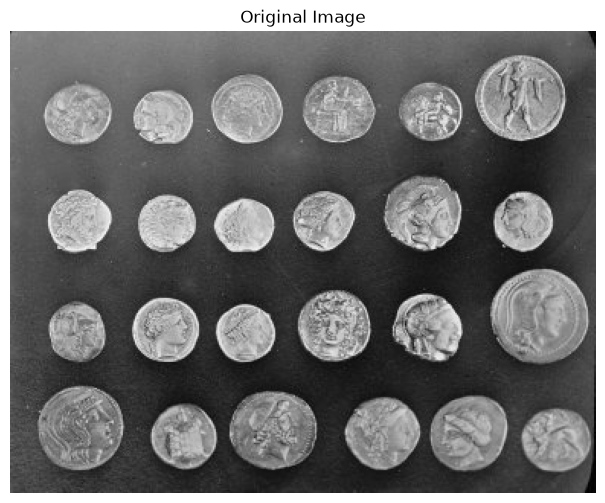

In [14]:
plt.figure(figsize=(15,6))
plt.imshow(img,cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

In [24]:


demo_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
],dtype=np.float32)/ 16.0

In [25]:
test_row,test_col=150,150

In [26]:
patch=img[test_row-1:test_row + 2,test_col-1:test_col + 2 ]
correlation_at_pixel=np.sum(patch * demo_kernel)


In [49]:
flipped_kernel=np.flip(demo_kernel)
convolution_at_pixel=np.sum(patch * flipped_kernel)

 #### *********NOTE: ICA02: sharpening,smoothing,histo Equalization********* 

In [50]:
print(f"At pixel({test_row},{test_col}):")
print("Manual Correlation result :",correlation_at_pixel)
print("Manual Convolution result :",convolution_at_pixel)
print("(For a SYMMETRIC kernal like this one, correlation and convolution)")
print("give the same result)")

At pixel(150,150):
Manual Correlation result : 39.625
Manual Convolution result : 39.625
(For a SYMMETRIC kernal like this one, correlation and convolution)
give the same result)


In [51]:
asymmetric_kernel=np.array([[1,2,3],
                            [0,0,0],
                            [-1,-2,-3]],dtype=np.float32)

In [52]:
correlation_asym=np.sum(patch*asymmetric_kernel)
convolution_asyum=np.sum(patch*np.flip(asymmetric_kernel))

In [53]:
print("\n with a non-symmetric kernal:")
print("Correlation Result:",correlation_asym)
print("Convolution result:",convolution_asyum)
print("These differ because convoltion flips the kernel first")


 with a non-symmetric kernal:
Correlation Result: -20.0
Convolution result: 12.0
These differ because convoltion flips the kernel first


In [54]:
correlated_full_cv2=cv2.filter2D(img,-1,demo_kernel)

In [55]:
flipped_demo_kernel=np.flip(demo_kernel)
convolved_full_cv2=cv2.filter2D(img,-1, flipped_demo_kernel)

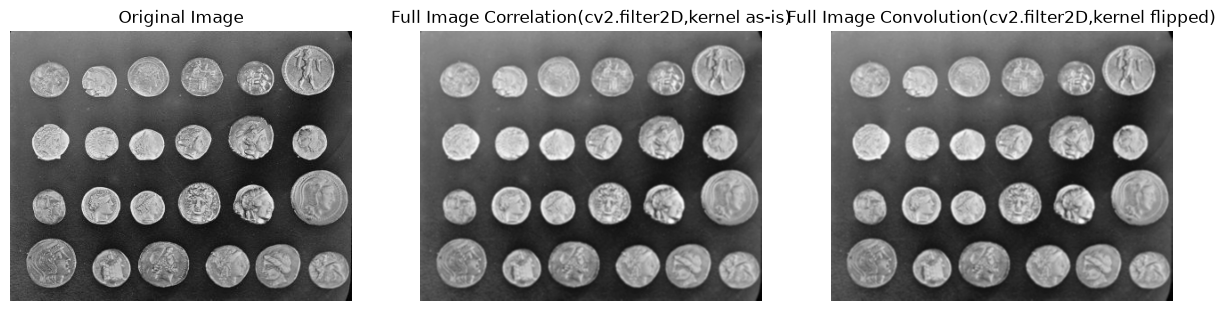

In [57]:
plt.figure(figsize=(15,6))
plt.subplot(1,3,1)
plt.imshow(img,cmap="gray")
plt.title("Original Image")
plt.axis("off")


plt.subplot(1,3,2)
plt.imshow(correlated_full_cv2,cmap="gray")
plt.title("Full Image Correlation(cv2.filter2D,kernel as-is)")
plt.axis("off")


plt.subplot(1,3,3)
plt.imshow(convolved_full_cv2,cmap="gray")
plt.title("Full Image Convolution(cv2.filter2D,kernel flipped)")
plt.axis("off")


plt.show()

In [60]:
kernel_3=np.ones((3,3),dtype=np.float32)/9
kernel_7=np.ones((3,3),dtype=np.float32)/49
kernel_15=np.ones((3,3),dtype=np.float32)/225

In [61]:
result_3=cv2.filter2D(img,-1,kernel_3)
result_7=cv2.filter2D(img,-1,kernel_7)
result_15=cv2.filter2D(img,-1,kernel_15)

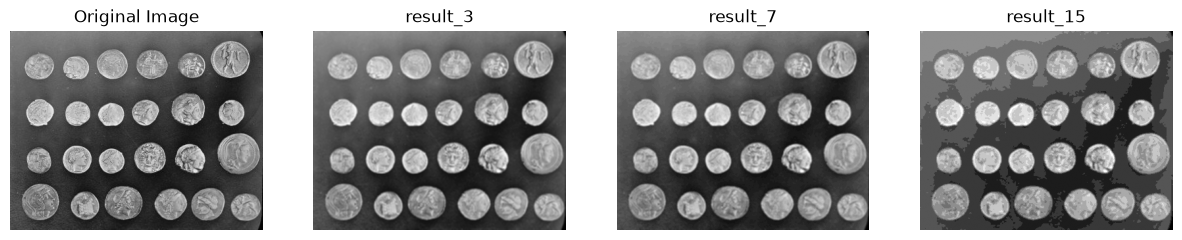

In [62]:
plt.figure(figsize=(15,6))
plt.subplot(1,4,1)
plt.imshow(img,cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(result_3,cmap="gray")
plt.title("3 x 3 kernel")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(result_7,cmap="gray")
plt.title("7 x 7 kernel")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(result_15,cmap="gray")
plt.title("15 x 15 kernel")
plt.axis("off")
plt.show()